<a href="https://colab.research.google.com/github/vzavala/DoE/blob/main/Python/ch6_hougen_watson_kernel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the course's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('doe'):
        os.system('git clone -q -b main --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DoE.git doe')
        os.system('git -C doe sparse-checkout set Python/Data Python/Support')
    path = 'doe/Python/'

Kernel model for the Hougen-Watson data (Victor Z and Ugochukwu Ikegwu, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $x_\omega$, $y_\omega$ | `X`, `y` | partial pressures and reaction rates |
| $k(x_\omega,x_{\omega'})=\exp(-\gamma\lVert x_\omega-x_{\omega'}\rVert^2)$ | `rbf(xi, xj, gamma)` | RBF kernel |
| $\mathbf{K}$, $\lambda$ | `K`, `lam` | kernel matrix and regularization |
| $\hat{\mathbf{y}}=\mathbf{K}(\mathbf{K}+\lambda I)^{-1}\mathbf{y}$ | `y_hat` | kernel prediction |

**Note:** This notebook reproduces Example 6.23 (Section 6.5) of *Statistics for Chemical Engineers*: a kernel model of the Hougen-Watson reaction rate for different kernel parameters gamma.

**The concept.** A kernel model writes the prediction as a combination of similarities to the data, $\hat{y}(x)=\sum_{\omega}\beta_\omega\,k(x,x_\omega)$. With a ridge penalty the weights are $\hat{\beta}=(\mathbf{K}+\lambda I)^{-1}\mathbf{y}$, so $\hat{\mathbf{y}}=\mathbf{K}\hat{\beta}$. The kernel replaces a set of basis functions that we never write explicitly, and the number of weights equals the number of data.

In the RBF kernel, $\gamma$ sets how fast similarity decays with distance. If $\gamma$ is large, every point is similar only to itself ($\mathbf{K}\to I$: interpolation, no generalization). If $\gamma$ is small, all points look alike ($\mathbf{K}\to\mathbf{1}\mathbf{1}^T$: the model loses detail).

In [2]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt(path+'Data/hougenwatson.dat')
X, y = data[:, :3], data[:, -1]
S = len(y)
lam = 0.01

def rbf(xi, xj, gamma):
    return np.exp(-gamma * np.sum((xi - xj)**2))

**From equation to code.** `K` is built entry by entry from the kernel, and `np.linalg.solve(K + lam*I, y)` computes the weights $\hat{\beta}=(\mathbf{K}+\lambda I)^{-1}\mathbf{y}$.

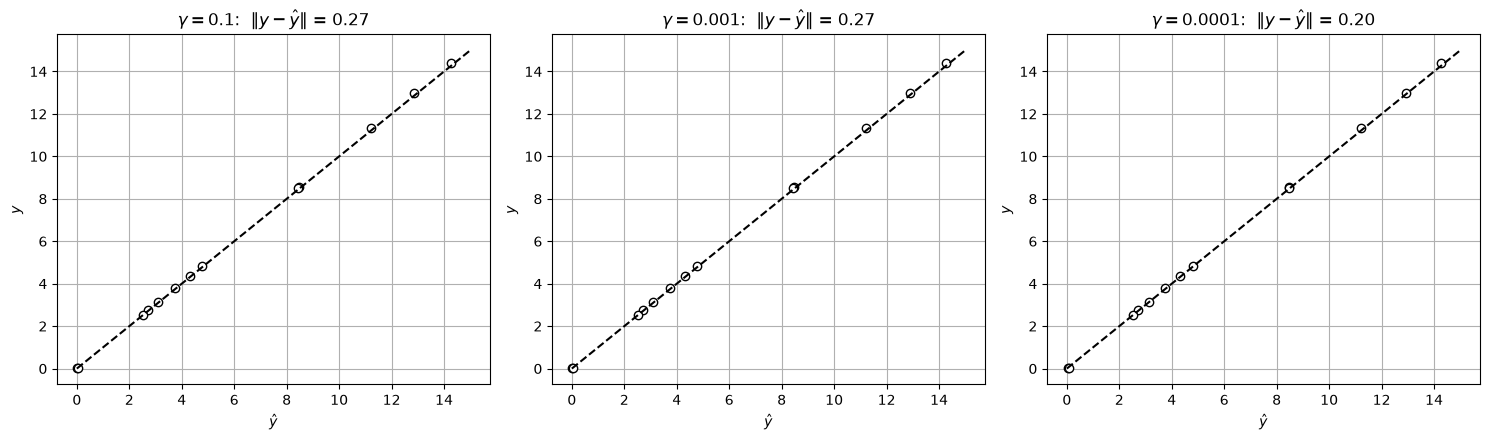

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, gamma in zip(axs, (0.1, 0.001, 0.0001)):
    K = np.array([[rbf(X[i], X[j], gamma) for j in range(S)] for i in range(S)])
    y_hat = K @ np.linalg.solve(K + lam * np.eye(S), y)
    ax.plot(y_hat, y, 'ko', markerfacecolor='w')
    ax.plot([0, 15], [0, 15], 'k--')
    ax.set_title(rf'$\gamma={gamma}$:  $\|y-\hat{{y}}\|$ = {np.linalg.norm(y - y_hat):.2f}')
    ax.set_xlabel(r'$\hat{y}$'); ax.set_ylabel('$y$')
    ax.grid(True)
plt.tight_layout()
plt.show()

**Fit against generalization.** Leaving one experiment out and predicting it has a closed form for this model: with the hat matrix $\mathbf{A}=\mathbf{K}(\mathbf{K}+\lambda I)^{-1}$, the prediction error is $(y_\omega-\hat{y}_\omega)/(1-\mathbf{A}_{\omega\omega})$. A small residual with a large leave-one-out error is overfitting.

In [4]:
for gamma in (0.1, 0.001, 0.0001):
    K = np.array([[rbf(X[i], X[j], gamma) for j in range(S)] for i in range(S)])
    A = K @ np.linalg.inv(K + lam * np.eye(S))
    e = y - A @ y
    print(f"gamma = {gamma:<7}: residual norm = {np.linalg.norm(e):5.2f},  leave-one-out norm = {np.linalg.norm(e / (1 - np.diag(A))):6.2f}")

gamma = 0.1    : residual norm =  0.27,  leave-one-out norm =  27.02
gamma = 0.001  : residual norm =  0.27,  leave-one-out norm =  26.91
gamma = 0.0001 : residual norm =  0.20,  leave-one-out norm =  17.55


**Note:** The fit is rather insensitive to gamma: the residuals are small in the three cases. The leave-one-out errors are much larger and depend on gamma, so the kernel parameter must be tuned for prediction, not for fit.